In [1]:
import sys
import pandas as pd
import importlib
from rnacorex import RNACOREX

data_train = pd.read_csv(f"../GPB/Data/train_brca_lognorm.csv", index_col=0)
data_test = pd.read_csv(f"../GPB/Data/test_brca_lognorm.csv", index_col=0)

X_train = data_train.drop("Class", axis=1)
y_train = data_train["Class"]
X_test = data_test.drop("Class", axis=1)
y_test = data_test["Class"]

In [ ]:
# Train a model with 20 interactions. The shown parameters are optional, they are represented at their default values.

rnacorex = RNACOREX(
        n_con=20,
        precision = 10,
        model = 'LGBN',
        mirna = True,
        mrna = True,
        lncrna = True,
        engine = None, 
        mode = 'alternating', 
        # weight = 0.5,             # only required for mode = 'weighted' 
        ties = 'isolated'
    )

# # Fit the model

rnacorex.fit(X_train, y_train)


# Train models from 20 to 40 interactions.

rnacorex_multi = RNACOREX(
        n_con=(20, 40)
    )

rnacorex_multi.fit(X_train, y_train)


# # Train models with 20 and 40 interactions.

rnacorex_multi2 = RNACOREX(
        n_con=[20, 40]
    )

rnacorex_multi2.fit(X_train, y_train)


USING DEFAULT ENGINE


Fitting models: 100%|██████████| 21/21 [00:01<00:00, 11.07model/s]


,n_con,"(20, ...)"
,precision,10
,model,'LGBN'
,mirna,True
,mrna,True
,lncrna,True
,engine,None
,mode,'alternating'
,weight,0.5
,ties,'isolated'
Name,Type,Value


In [ ]:
# PREDICTION WITH COMPLETE EVIDENCE

rl = rnacorex.predict(X_test)

# PREDICTION WITH PARTIAL EVIDENCE

X_test_partial = X_test.sample(frac=0.9, axis=1, random_state=42)

rl_part = rnacorex.predict(X_test_partial)

Predicting:  14%|█▍        | 3/21 [00:00<00:00, 26.19model/s]

K: 20  Predicting with complete evidence.
K: 21  Predicting with complete evidence.
K: 22  Predicting with complete evidence.
K: 23  Predicting with complete evidence.
K: 24  Predicting with complete evidence.
K: 25  Predicting with complete evidence.


Predicting:  43%|████▎     | 9/21 [00:00<00:00, 22.92model/s]

K: 26  Predicting with complete evidence.
K: 27  Predicting with complete evidence.
K: 28  Predicting with complete evidence.
K: 29  Predicting with complete evidence.
K: 30  Predicting with complete evidence.


Predicting:  57%|█████▋    | 12/21 [00:00<00:00, 21.82model/s]

K: 31  Predicting with complete evidence.
K: 32  Predicting with complete evidence.
K: 33  Predicting with complete evidence.
K: 34  Predicting with complete evidence.


Predicting:  86%|████████▌ | 18/21 [00:00<00:00, 19.18model/s]

K: 35  Predicting with complete evidence.
K: 36  Predicting with complete evidence.
K: 37  Predicting with complete evidence.
K: 38  Predicting with complete evidence.


Predicting: 100%|██████████| 21/21 [00:01<00:00, 19.75model/s]

K: 39  Predicting with complete evidence.
K: 40  Predicting with complete evidence.


In [ ]:
# GET INTERACTION RANKING

rnacorex.get_interactions(20)

,Node1,Node2,Type1,Type2,SMI,FMI
0,hsa-mir-429,LMO7,miRNA,mRNA,0.981076,0.047948
1,COL4A1,COL4A2,mRNA,mRNA,0.000100,1.175261
2,hsa-mir-429,TGFBI,miRNA,mRNA,0.981076,0.045414
3,LAMA4,NID2,mRNA,mRNA,0.000100,1.141954
4,hsa-mir-421,HMGA2,miRNA,mRNA,0.981076,0.047236
5,SAA1,SAA2,mRNA,mRNA,0.000100,0.850799
6,hsa-mir-592,LDLR,miRNA,mRNA,0.981076,0.031802
7,C1QA,C1QC,mRNA,mRNA,0.000100,0.727701
8,hsa-mir-2110,TRA2A,miRNA,mRNA,0.981076,0.040435
9,COL4A1,NID2,mRNA,mRNA,0.000100,0.533485


In [ ]:
# GET FITTED MODEL

model = rnacorex.model_

# WHEN MORE THAN ONE MODEL HAS BEEN FITTED, YOU CAN ACCESS THE CORRESPONDING DATA IN MODELS_ BY SELECTING THE NUMBER OF INTERACTIONS

model25 = rnacorex_multi.models_[25]

model35 = rnacorex_multi.models_[35]

KeyError: 20

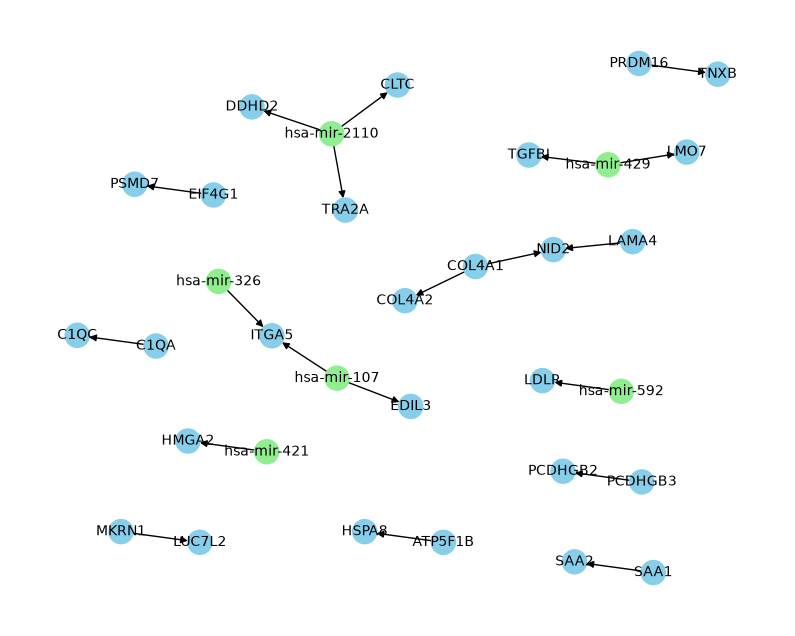

,n_con,20
,precision,10
,model,'LGBN'
,mirna,True
,mrna,True
,lncrna,True
,engine,None
,mode,'alternating'
,weight,0.5
,ties,'isolated'
Name,Type,Value


In [15]:
# RAW NETWORK

G = rnacorex.model_['G']

rnacorex.display(G)

In [ ]:
# EXTRACT AND DISPLAY MPC NETWORK

maps = rnacorex.mpc(
    display=True,             
    c=0,                
    k=20,
    th=0.25
)

[[ 9.21838525 11.60026344 10.6532512  10.54652433 16.13883905 15.00334286
   9.62149108 12.46702533 14.77294392 13.14172034 11.15137376 11.55129776
  12.99012703  5.80857871 14.56497972 10.97454932  8.13286363 15.22858748
   5.29916122  5.76625267 12.66935923 10.83019293  3.97368371 10.85726696
  12.44609504 12.45717682 12.61814919  4.4708705  10.57448318 12.04810741
   9.1215824  12.23857481  9.13421377 14.76427486  6.68287678  5.24288852
   5.88152721  1.54676934  3.0840082   2.03806994  6.79001832  1.94239045
   2.42225299]
 [ 9.6426828  11.87198628 10.14015384 10.20032726 15.83134652 14.81467885
  10.00187304 12.0497503  14.5572346  12.84269071 11.0029872  11.42378673
  13.28565904  6.26156736 14.23818776 10.80104531  8.01554175 15.04721636
   5.34567305  5.19630221 12.49571681 11.0470785   3.92878905 11.23018815
  11.98308668 12.21313048 12.32385606  4.45582395 10.25152167 12.26971302
   8.61893903 11.78698175  9.79328793 14.39087643  6.01770428  4.4442799
   5.97215024  1.7109124